In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pandas basic 

In [3]:
df = pd.read_csv("../Datasets/workout_data.csv")

In [4]:
df.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020/12/01,110,130,409.1
1,60,2020/12/02,117,145,479.0
2,60,2020/12/03,103,135,340.0
3,45,2020/12/04,109,175,282.4
4,45,2020/12/05,117,148,406.0


In [5]:
df.tail()

,Duration,Date,Pulse,Maxpulse,Calories
27,60,2020/12/27,92,118,241.0
28,60,2020/12/28,103,132,NaN
29,60,2020/12/29,100,132,280.0
30,60,2020/12/30,102,129,380.3
31,60,2020/12/31,92,115,243.0


# Understand the data

In [6]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     str    
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), str(1)
memory usage: 1.4 KB


In [7]:
df.shape

(32, 5)

In [8]:
df.sample(5)

,Duration,Date,Pulse,Maxpulse,Calories
19,60,2020/12/19,103,123,323.0
3,45,2020/12/04,109,175,282.4
11,60,2020/12/12,100,120,250.7
9,60,2020/12/10,98,124,269.0
16,60,2020/12/16,98,120,215.2


In [9]:
# Check column names

In [10]:
df.columns

Index(['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories'], dtype='str')

In [11]:
df.dtypes

Duration      int64
Date            str
Pulse         int64
Maxpulse      int64
Calories    float64
dtype: object

In [12]:
df.describe(include='all')

,Duration,Date,Pulse,Maxpulse,Calories
count,32.000000,31,32.000000,32.000000,30.000000
unique,NaN,30,NaN,NaN,NaN
top,NaN,2020/12/12,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN
mean,68.437500,NaN,103.500000,128.500000,304.680000
std,70.039591,NaN,7.832933,12.998759,66.003779
min,30.000000,NaN,90.000000,101.000000,195.100000
25%,60.000000,NaN,100.000000,120.000000,250.700000
50%,60.000000,NaN,102.500000,127.500000,291.200000
75%,60.000000,NaN,106.500000,132.250000,343.975000


# Data quality check

This is one of the most important parts of EDA.



In [13]:
df.isnull().sum()

Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

In [14]:
# missing values percentage

In [15]:
# I am adding the mean and median for the missing values

In [16]:
missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent.sort_values(ascending=False))

Calories    6.250
Date        3.125
Duration    0.000
Pulse       0.000
Maxpulse    0.000
dtype: float64


In [18]:
# visualize the missing values

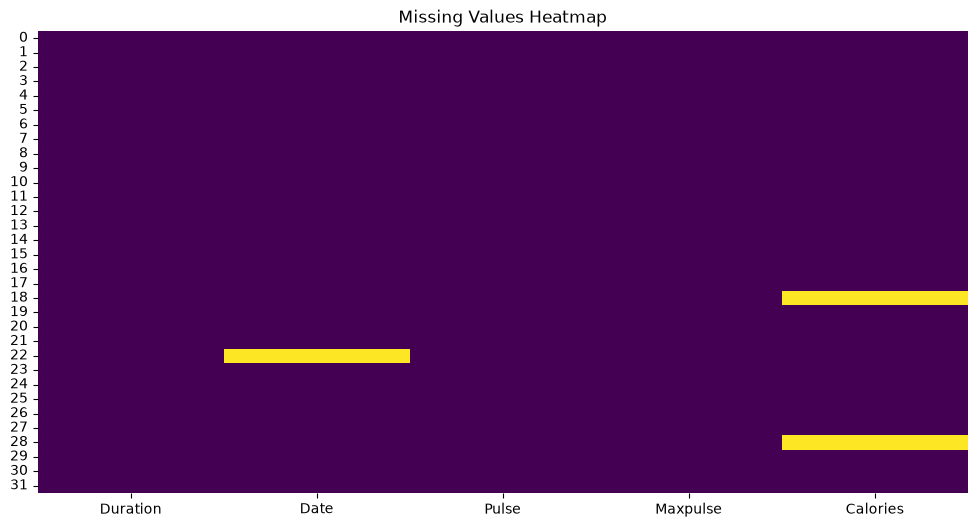

In [19]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title('Missing Values Heatmap')
plt.show()

In [20]:
df = df.ffill()

In [21]:
df = df.bfill()

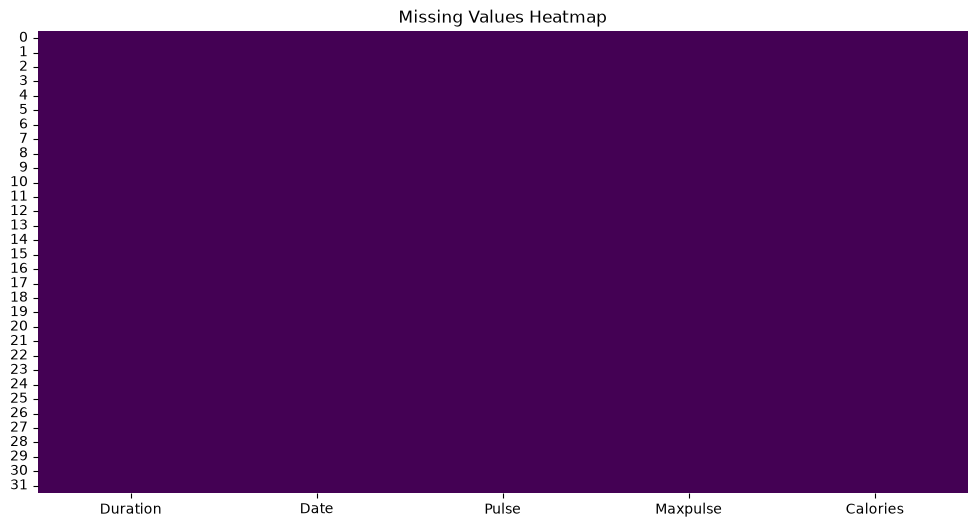

In [22]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title('Missing Values Heatmap')
plt.show()

In [25]:
# check for the duplicates

df.duplicated().sum()

np.int64(1)

In [28]:
# Drop duplicate
# df.drop_duplicated()

# First find the duplicate

dfDupicated = df[df.duplicated()]
dfDupicated

,Duration,Date,Pulse,Maxpulse,Calories
12,60,2020/12/12,100,120,250.7


In [29]:
df = df.drop_duplicates()

In [30]:
df.duplicated().sum()

np.int64(0)

# Extra spaces
# Different spellings
# In consistent capitalization
# Invalid category labeling

# Universal analysis

# Check for the outliers

Text(0, 0.5, 'Duration value')

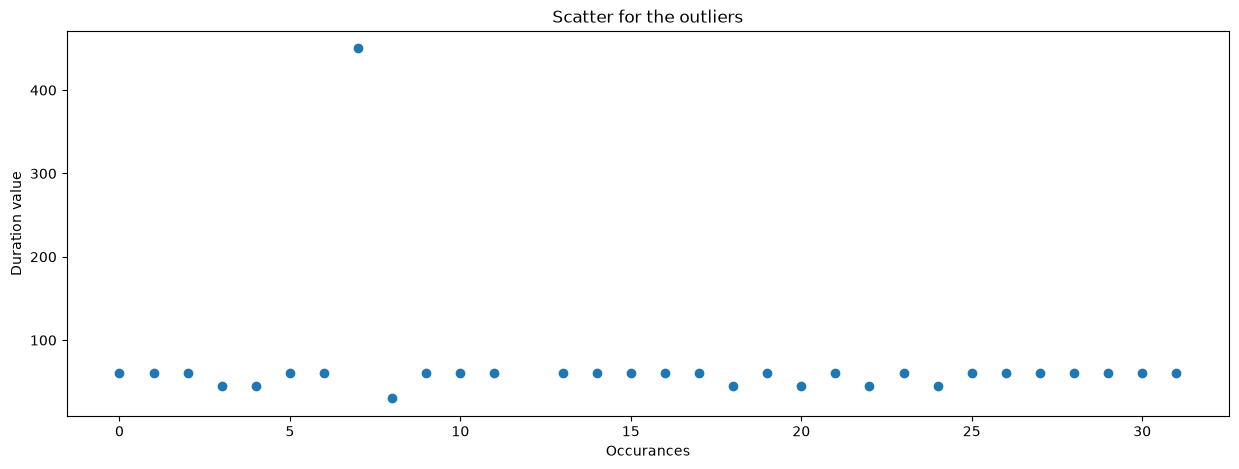

In [33]:
# Use scatter plot for the outliers

plt.figure(figsize=(15, 5))

plt.scatter(df.index, df["Duration"])
plt.title("Scatter for the outliers")
plt.xlabel("Occurances")
plt.ylabel("Duration value")

In [35]:
# Safe removing process of the rows: 

# find the row

removee = df[df["Duration"] > 100]
removee

,Duration,Date,Pulse,Maxpulse,Calories
7,450,2020/12/08,104,134,253.3


In [37]:
df = df.drop(removee.index)

Text(0, 0.5, 'Duration value')

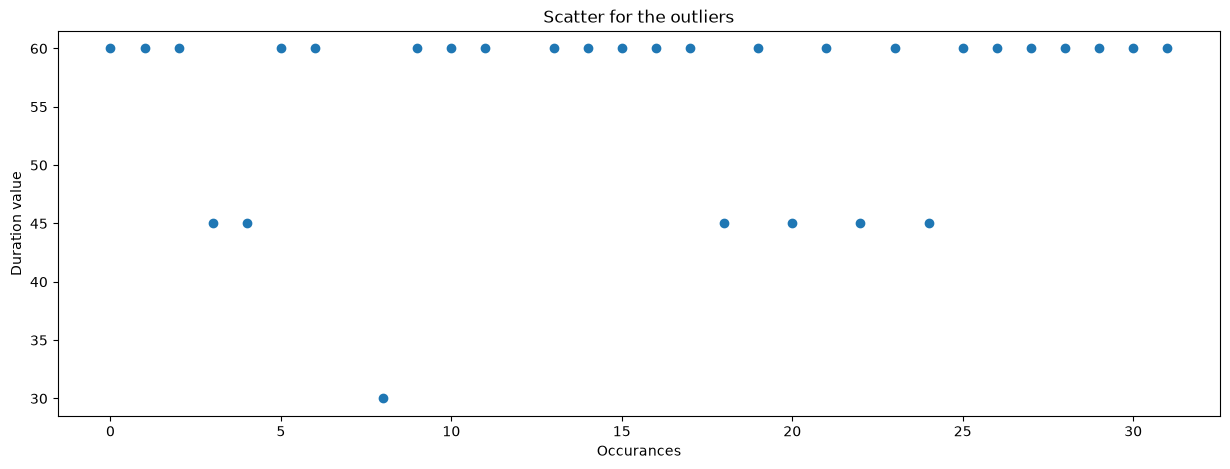

In [38]:
plt.figure(figsize=(15, 5))

plt.scatter(df.index, df["Duration"])
plt.title("Scatter for the outliers")
plt.xlabel("Occurances")
plt.ylabel("Duration value")

In [39]:
df.describe()

,Duration,Pulse,Maxpulse,Calories
count,30.000000,30.000000,30.000000,30.000000
mean,56.000000,103.600000,128.600000,305.913333
std,7.812457,8.071235,13.306985,65.604913
min,30.000000,90.000000,101.000000,195.100000
25%,60.000000,100.000000,120.000000,250.175000
50%,60.000000,102.500000,127.500000,300.000000
75%,60.000000,107.500000,132.000000,343.975000
max,60.000000,130.000000,175.000000,479.000000
